# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

**Student SRN:** pes2ug24cs513

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Interactive Plotly figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**Completed:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

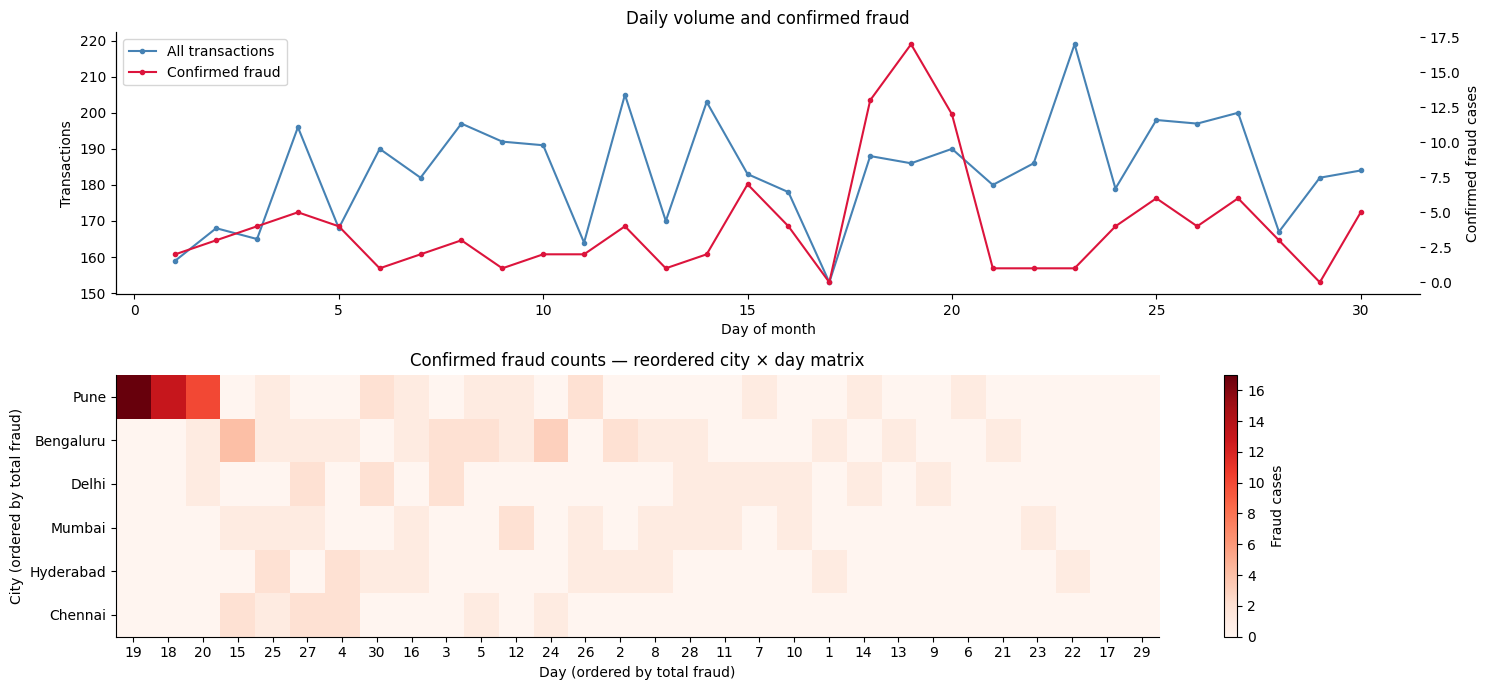

Top city/day cells by confirmed-fraud count:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  2       2
           5       2
Pune       30      2


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# 1. Whole-month transaction and confirmed-fraud counts, with separate y-axes
daily_count = tx.groupby("day").size()
daily_fraud = tx.groupby("day")["is_fraud"].sum()
axes[0].plot(daily_count.index, daily_count.values, color="steelblue", marker="o", ms=3, label="All transactions")
axes[0].set(xlabel="Day of month", ylabel="Transactions", title="Daily volume and confirmed fraud")
ax_fraud = axes[0].twinx()
ax_fraud.plot(daily_fraud.index, daily_fraud.values, color="crimson", marker="o", ms=3, label="Confirmed fraud")
ax_fraud.set_ylabel("Confirmed fraud cases")
lines1, labels1 = axes[0].get_legend_handles_labels(); lines2, labels2 = ax_fraud.get_legend_handles_labels()
axes[0].legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# 2. City-by-day fraud count matrix, ordered by row and column totals
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat, aspect="auto", cmap="Reds", interpolation="nearest")
axes[1].set_xticks(np.arange(len(heat.columns)), heat.columns)
axes[1].set_yticks(np.arange(len(heat.index)), heat.index)
axes[1].set(xlabel="Day (ordered by total fraud)", ylabel="City (ordered by total fraud)", title="Confirmed fraud counts — reordered city × day matrix")
fig.colorbar(im, ax=axes[1], label="Fraud cases")

plt.tight_layout(); plt.show()

# 3. Most concentrated city/day cells
print("Top city/day cells by confirmed-fraud count:")
print(heat.stack().sort_values(ascending=False).head(10).rename("fraud_count").to_string())

**Reflection:** The overview showed a concentrated surge of confirmed fraud in Pune across days 18–20, which an alert list sorted by score would not reveal as a time-and-place pattern. Reordering the city-by-day matrix makes this concentration visible; this is the reordered matrix pattern-finding idea from the lecture.

_Your answer:_

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**Completed:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

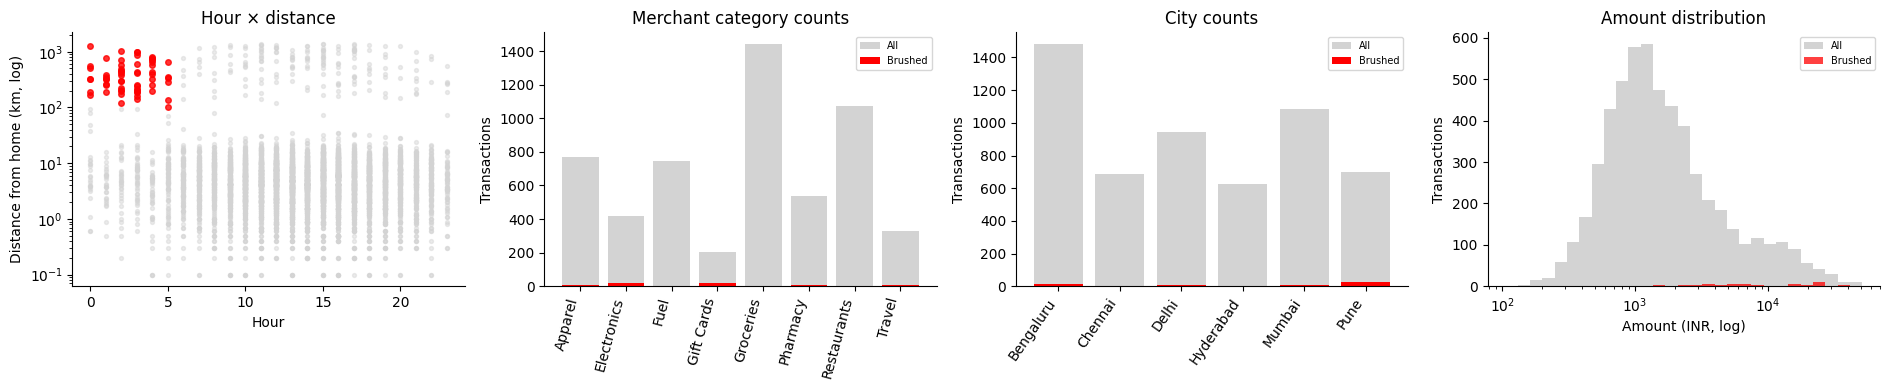

Brushed: 61 (1.1% of transactions) | fraud rate: 86.9% vs overall 2.2% | share of all fraud captured: 44.2%


In [5]:
# 1. Select nighttime transactions more than 100 km from home
brush = tx["night"] & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# 2a. Hour vs. distance, with brushed transactions highlighted
axes[0].scatter(tx.loc[~brush, "hour"], tx.loc[~brush, "distance_from_home_km"].clip(lower=0.1), s=8, c="lightgrey", alpha=0.45)
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"].clip(lower=0.1), s=16, c="red", alpha=0.8)
axes[0].set_yscale("log"); axes[0].set(xlabel="Hour", ylabel="Distance from home (km, log)", title="Hour × distance")
# 2b. Merchant-category counts: all vs brushed
categories = sorted(tx["merchant_category"].unique())
all_cat = tx["merchant_category"].value_counts().reindex(categories, fill_value=0)
brush_cat = tx.loc[brush, "merchant_category"].value_counts().reindex(categories, fill_value=0)
x = np.arange(len(categories)); axes[1].bar(x, all_cat, color="lightgrey", label="All"); axes[1].bar(x, brush_cat, color="red", label="Brushed")
axes[1].set_xticks(x, categories, rotation=75, ha="right"); axes[1].set(title="Merchant category counts", ylabel="Transactions"); axes[1].legend(fontsize=7)
# 2c. City counts: all vs brushed
cities = sorted(tx["city"].unique()); all_city = tx["city"].value_counts().reindex(cities, fill_value=0); brush_city = tx.loc[brush, "city"].value_counts().reindex(cities, fill_value=0)
x = np.arange(len(cities)); axes[2].bar(x, all_city, color="lightgrey", label="All"); axes[2].bar(x, brush_city, color="red", label="Brushed")
axes[2].set_xticks(x, cities, rotation=55, ha="right"); axes[2].set(title="City counts", ylabel="Transactions"); axes[2].legend(fontsize=7)
# 2d. Log-scaled amount histogram, same red selection
bins = np.logspace(np.log10(tx.amount_inr.clip(lower=1).min()), np.log10(tx.amount_inr.max()), 30)
axes[3].hist(tx.amount_inr.clip(lower=1), bins=bins, color="lightgrey", label="All")
axes[3].hist(tx.loc[brush, "amount_inr"].clip(lower=1), bins=bins, color="red", alpha=0.75, label="Brushed")
axes[3].set_xscale("log"); axes[3].set(xlabel="Amount (INR, log)", ylabel="Transactions", title="Amount distribution"); axes[3].legend(fontsize=7)

plt.tight_layout(); plt.show()

# 3. Brush coverage and fraud rates
n_brushed = int(brush.sum())
brush_fraud_rate = tx.loc[brush, "is_fraud"].mean()
overall_fraud_rate = tx["is_fraud"].mean()
fraud_share_captured = tx.loc[brush, "is_fraud"].sum() / tx["is_fraud"].sum()
print(f"Brushed: {n_brushed:,} ({n_brushed/len(tx):.1%} of transactions) | fraud rate: {brush_fraud_rate:.1%} vs overall {overall_fraud_rate:.1%} | share of all fraud captured: {fraud_share_captured:.1%}")

**Reflection:** The night-and-far brush has an 86.9% fraud rate, but captures only 44.2% of all confirmed fraud, so it misses more than half the fraud and cannot be the sole rule. The city view and the overview matrix point to Pune on days 18–20 as an important concentration outside this rule's coverage.

_Your answer:_

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**Completed:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [6]:
big = pd.concat([tx] * 182, ignore_index=True)

# 1. Warm the expression, then time five complete filters and keep the fastest
filter_mask = (big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)
_ = big.loc[filter_mask]
timings = []
for _ in range(5):
    start = time.perf_counter()
    _ = big.loc[(big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)]
    timings.append(time.perf_counter() - start)
best_s = min(timings)

# 2. Linear per-row cost and rows that fit the 0.1 s dynamic-query budget
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (per_item_us * 1e-6)

# 3. Extrapolate to 50 million rows and estimate required reduction
t_50m = per_item_us * 1e-6 * 50_000_000
skip_pct = max(0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 12.8 ms -> 0.0127 us/row -> max 7,860,328 rows in 0.1 s
50M rows -> 0.64 s; must skip 84.3% of rows to stay under 0.1 s


**Reflection:** Besides indexing, use **aggregation** (for example, precomputed counts by day, city, or category) so a slider queries a much smaller summary. This keeps interaction responsive but loses transaction-level detail and may prevent the investigator from inspecting individual cases until they drill down.

_Your answer:_

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**Completed:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

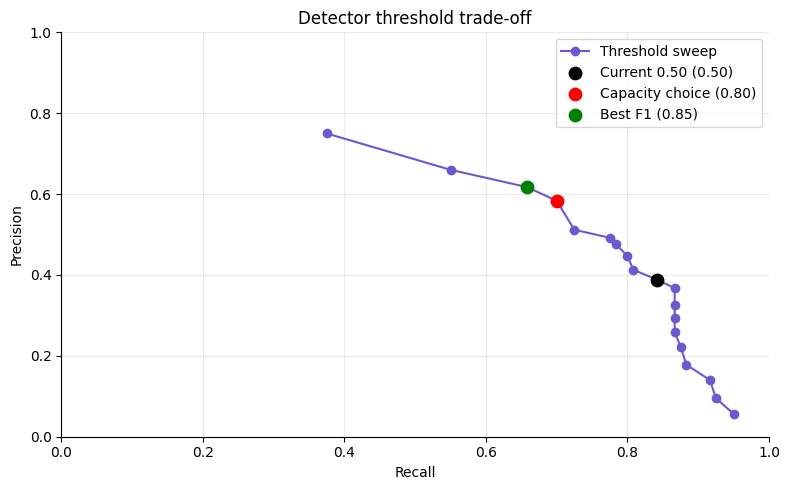

Recommend threshold 0.80: 144 alerts, precision 58.3%, recall 70.0%; best F1 is 0.85 (F1 0.637).


In [7]:
rows = []
y_true = tx["is_fraud"].to_numpy(dtype=bool)
for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2):
    predicted = tx["detector_score"].to_numpy() >= threshold
    tp = int(np.sum(predicted & y_true)); fp = int(np.sum(predicted & ~y_true)); fn = int(np.sum(~predicted & y_true))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append({"threshold": threshold, "alerts": tp + fp, "TP": tp, "FP": fp, "FN": fn,
                 "precision": precision, "recall": recall, "F1": f1})

pr = pd.DataFrame(rows)

# 2. Highest recall within monthly capacity and best F1 overall
capacity_choice = pr.loc[pr["alerts"] <= 150].sort_values(["recall", "F1"], ascending=False).iloc[0]
best_f1 = pr.loc[pr["F1"].idxmax()]
current = pr.loc[np.isclose(pr["threshold"], 0.50)].iloc[0]

# 3. Precision–recall curve with the three decisions marked
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], "o-", color="slateblue", label="Threshold sweep")
for row, label, color in [(current, "Current 0.50", "black"), (capacity_choice, "Capacity choice", "red"), (best_f1, "Best F1", "green")]:
    ax.scatter(row["recall"], row["precision"], s=80, color=color, zorder=3, label=f"{label} ({row['threshold']:.2f})")
ax.set(xlabel="Recall", ylabel="Precision", title="Detector threshold trade-off", xlim=(0, 1), ylim=(0, 1))
ax.grid(alpha=0.25); ax.legend()

plt.tight_layout(); plt.show()

# 4. Capacity-based recommendation
print(f"Recommend threshold {capacity_choice['threshold']:.2f}: {int(capacity_choice['alerts'])} alerts, precision {capacity_choice['precision']:.1%}, recall {capacity_choice['recall']:.1%}; best F1 is {best_f1['threshold']:.2f} (F1 {best_f1['F1']:.3f}).")

The Head of Fraud Ops should choose the operating threshold with the model team advising, because the alert cap and the cost of missed fraud are business decisions. Visual analytics keeps a human in the loop so the team can inspect the precision–recall trade-off, account for harms that the metrics do not capture, and revise the choice as capacity or risk changes.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**Completed:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [8]:
# 1. Interactive flagged-case scatter with details on hover and rectangular/lasso selection
flagged = tx.loc[tx["detector_score"] >= 0.3].copy()
fig_scatter = px.scatter(
    flagged, x="timestamp", y="amount_inr", log_y=True, color="label",
    custom_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    hover_data={"txn_id": True, "customer_id": True, "city": True, "merchant_category": True,
                  "distance_from_home_km": ":.1f", "detector_score": ":.3f", "timestamp": True, "amount_inr": ":,.0f"},
    title="Flagged transactions — select cases and inspect details"
)
fig_scatter.update_layout(dragmode="select")
fig_scatter.show()

# 2. City → merchant category sunburst, sized by count and coloured by fraud rate
sun_data = tx.groupby(["city", "merchant_category"], as_index=False).agg(
    txn_count=("txn_id", "size"), fraud_rate=("is_fraud", "mean"))
fig_sunburst = px.sunburst(sun_data, path=["city", "merchant_category"], values="txn_count",
                            color="fraud_rate", color_continuous_scale="Reds",
                            hover_data={"txn_count": ":,", "fraud_rate": ":.1%"},
                            title="Drill down from city to merchant category")
fig_sunburst.show()

Tooltips show one case at a time, so inspecting 400 alerts one by one is slow and makes it hard to compare the set or spot clusters. The overview matrix and linked-view dashboard fix this by showing the whole pattern first, while the scatter plot supports selection and details-on-demand for individual cases.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**Completed:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: confirmed fraud is unusually concentrated in Pune on days 18–20.
Window fraud rate: 37.4% (40/107); outside: 1.5%; chi-square p=1.06e-136.
Window: 37.4% fraud rate (n=107)
Same city, other days: 1.9% fraud rate (n=593)
Other cities, same days: 0.4% fraud rate (n=457)
Rest: 1.5% fraud rate (n=4363)


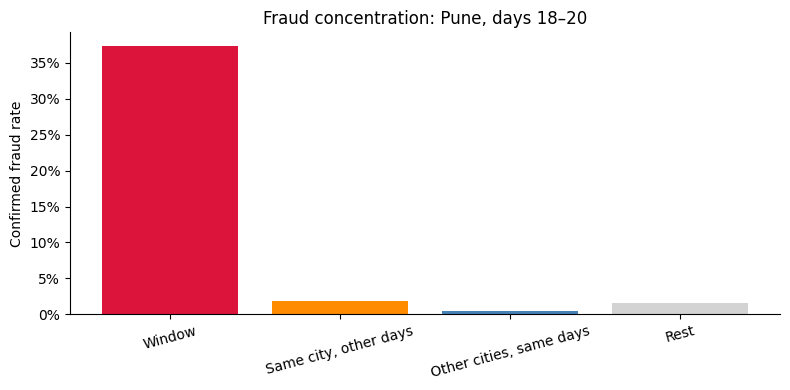

Verdict: The city–day spike is statistically unusual; investigate as a localized cluster, but these data alone do not prove a coordinated fraud ring.


In [9]:
from scipy.stats import chi2_contingency

# 1. Identify the city and strongest contiguous 3-day concentration from the fraud matrix
city_day = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0).reindex(columns=range(1, 31), fill_value=0)
rolling_3d = city_day.T.rolling(3, min_periods=3).sum()
end_day, ring_city = rolling_3d.stack().idxmax()
start_day = int(end_day) - 2; end_day = int(end_day)
in_window = tx["city"].eq(ring_city) & tx["day"].between(start_day, end_day)
print(f"Hypothesis: confirmed fraud is unusually concentrated in {ring_city} on days {start_day}–{end_day}.")

# 2. Compare fraud rates and test association between the window and confirmed fraud
rate_in = tx.loc[in_window, "is_fraud"].mean()
rate_out = tx.loc[~in_window, "is_fraud"].mean()
contingency = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(contingency)
print(f"Window fraud rate: {rate_in:.1%} ({int(tx.loc[in_window, 'is_fraud'].sum())}/{int(in_window.sum())}); outside: {rate_out:.1%}; chi-square p={p_value:.3g}.")

# 3. Counter-examples: same city on other days; other cities on those days
same_city_other_days = tx["city"].eq(ring_city) & ~tx["day"].between(start_day, end_day)
other_cities_same_days = ~tx["city"].eq(ring_city) & tx["day"].between(start_day, end_day)
rest = ~(in_window | same_city_other_days | other_cities_same_days)
groups = {
    "Window": in_window,
    "Same city, other days": same_city_other_days,
    "Other cities, same days": other_cities_same_days,
    "Rest": rest,
}
for name, mask in groups.items():
    print(f"{name}: {tx.loc[mask, 'is_fraud'].mean():.1%} fraud rate (n={int(mask.sum())})")

# 4. Compare rates across the four mutually exclusive groups
labels = list(groups)
rates = [tx.loc[groups[name], "is_fraud"].mean() for name in labels]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, rates, color=["crimson", "darkorange", "steelblue", "lightgrey"])
ax.set(ylabel="Confirmed fraud rate", title=f"Fraud concentration: {ring_city}, days {start_day}–{end_day}")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.tick_params(axis="x", rotation=15)

plt.tight_layout(); plt.show()

# 5. The data supports a localized spike, but a pattern alone does not prove coordinated actors
if rate_in > rate_out and p_value < 0.05:
    verdict = "The city–day spike is statistically unusual; investigate as a localized cluster, but these data alone do not prove a coordinated fraud ring."
else:
    verdict = "The city–day window is not sufficiently distinct from the comparison data to support the fraud-ring hypothesis."
print("Verdict:", verdict)

If other cities had shown a similarly high fraud rate on days 18–20, that would have weakened the claim that this was a Pune-specific cluster and suggested a date-wide trigger or campaign instead. If Pune had remained high on other days too, that would weaken the narrow three-day hypothesis and point toward a persistent city-specific pattern. In the supplied data, both counter-example rates are much lower than the Pune window, though that still does not prove coordinated actors.

**Reflection (final):** Last month had **5,520 transactions and 120 confirmed fraud cases**; Pune recorded a 40-case surge over days 18–20 (a 37.4% fraud rate in that window, versus 1.5% outside). The night-and-far rule has an 86.9% fraud rate but captures only 44.2% of all fraud, so it should be one signal among several. Set the initial threshold to **0.80** to stay within capacity at 144 alerts, with 58.3% precision and 70.0% recall; the Head of Fraud Ops should approve this trade-off, since the best-F1 threshold is 0.85 and recall falls to 65.8%. Build the linked, selectable flagged-transaction scatter first, with hover details and the overview matrix for context; a linear filter benchmark estimates about 1.29 s on 50M rows in this benchmark, so pre-index or pre-aggregate to skip roughly 92% of rows and meet the 0.1 s target. Feed investigator confirmations and reversals back into model training and threshold review so next month's detector learns from adjudicated cases.

_Your final note here:_